# 014. 출근시간대 기초통계

교수님 미팅에서 회귀 결과를 보여주기 전에 **출근시간 광역버스의 실제 승차 변화**를 먼저 확인한다.

- **승차시각 06:00:00 이상~10:00:00 미만**, 즉 **09:59:59까지 포함**한다.
- 2024-10-17 / 2025-11-06, 기존 공급구조 유지 250m 격자 **126개 전체**.
- 승차건수 = 교통카드 행 수. `utztn_nope` 합계나 임의 중복 제거는 사용하지 않는다.
- 전체·권역별 기초통계 → 격자별 분포 → 개통 전 규모와 변화율 → **노선별 변화율** 순서로 제시한다.
- 노선별 실적도 **126개 격자 내부 승차 기록만** 집계한다. 노선 전체 운행 구간 실적이 아니다.
- 기존 코드·원자료·결과표는 수정하지 않는다. 회귀·머신러닝 없이 표·그림만 출력하고 CSV·그림 파일을 별도 저장하지 않는다.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display

ROOT_014=next(p for p in [Path.cwd(),*Path.cwd().parents]
              if (p/'config.py').is_file() and (p/'code').is_dir())
ORDER_014=['운정중앙','킨텍스','대곡']
TIME_014='06:00~09:59:59'
COLORS_014={'감소':'#CB181D','유지':'#AAAAAA','증가':'#2166AC'}
REGION_COLORS_014={'운정중앙':'#3264A8','킨텍스':'#D18C32','대곡':'#359475'}
for font in [Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
             Path(r'C:\Windows\Fonts\malgun.ttf'),Path('/Library/Fonts/NanumGothic.ttf')]:
    if font.is_file():
        fm.fontManager.addfont(str(font))
        plt.rcParams['font.family']=fm.FontProperties(fname=str(font)).get_name()
        break
plt.rcParams.update({'axes.unicode_minus':False,'font.size':12,'figure.dpi':110,
                     'axes.titlesize':15,'axes.labelsize':12,
                     'axes.labelweight':'bold'})
pd.set_option('display.max_columns',30)
pd.set_option('display.max_rows',150)

# 실제 Bold 글꼴 파일을 우선 사용해 숫자와 한글 레이블 모두 굵게 표시한다.
BOLD_FONT_014=None
for bold_path in [Path.home()/'Library/Fonts/KoPubWorld Dotum Bold.ttf',
                  Path(r'C:\Windows\Fonts\malgunbd.ttf'),Path('/Library/Fonts/NanumGothicBold.ttf')]:
    if bold_path.is_file():
        fm.fontManager.addfont(str(bold_path))
        BOLD_FONT_014=fm.FontProperties(fname=str(bold_path))
        break

def bold_label_014(label):
    size=label.get_fontsize()
    if BOLD_FONT_014 is not None:
        label.set_fontproperties(BOLD_FONT_014)
        label.set_fontsize(size)
    label.set_fontweight('bold')

def clean_axes_014(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.set_axisbelow(True);ax.grid(axis='y',alpha=.18)
    # 축 눈금·축 제목·수치 라벨을 굵게 표시한다.
    for label in [*ax.get_xticklabels(), *ax.get_yticklabels(),
                  ax.xaxis.label, ax.yaxis.label, *ax.texts]:
        bold_label_014(label)
    ax.xaxis.get_offset_text().set_fontweight('bold')
    ax.yaxis.get_offset_text().set_fontweight('bold')
    legend=ax.get_legend()
    if legend is not None:
        for label in legend.get_texts():
            bold_label_014(label)

def morning_mask_014(t):
    return t.dt.hour.ge(6)&t.dt.hour.lt(10)

edge_test_014=pd.Series(pd.to_datetime(['2024-10-17 05:59:59','2024-10-17 06:00:00',
    '2024-10-17 09:00:00','2024-10-17 09:59:59','2024-10-17 10:00:00']))
assert morning_mask_014(edge_test_014).tolist()==[False,True,True,True,False]
base_014=pd.read_csv(ROOT_014/'data/final/gtx_a/S1_126격자_건수기준_기초표.csv',encoding='utf-8-sig').set_index('셀 ID')
stops_014=pd.read_csv(ROOT_014/'data/processed/gtx_a/16_새데이터_공급구조유지_250m격자.csv',dtype=str,encoding='utf-8-sig')
assert len(base_014)==126 and base_014.index.is_unique
assert set(base_014.index)==set(stops_014['셀 ID'].astype(int))
assert base_014.groupby('nearest_station').size().reindex(ORDER_014).tolist()==[63,26,37]
print('출근시간:',TIME_014,'· 9시대 포함 · 126개 격자 전체 유지')

출근시간: 06:00~09:59:59 · 9시대 포함 · 126개 격자 전체 유지


## 1. 원자료 재집계 및 기존 결과 일치 확인

조회일·운행일(`query_date`, `opr_ymd`)을 기준으로 날짜를 확인한다. 영업일 자료에 포함된 다음 날 자정 이후~6시 미만 기록은 종일 집계에서 유지하고, 출근시간에는 포함하지 않는다. 노선번호는 기존 011과 동일하게 `query_route_no`를 사용한다.

In [2]:
grid_014=base_014[['nearest_station','board_2024','board_2025']].copy()
all_selected_014={};morning_selected_014={};quality_014=[]
for year,filename,date in [
    (2024,'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv','20241017'),
    (2025,'gtx_a_transport_card_20251106_raw_with_coords.csv','20251106')]:
    raw=pd.read_csv(ROOT_014/'data/raw/gtx_a/transport_card'/filename,dtype=str,encoding='utf-8-sig')
    assert raw['query_date'].eq(date).all() and raw['opr_ymd'].eq(date).all()
    lookup=pd.DataFrame([(int(row['셀 ID']),sid) for _,row in stops_014.iterrows()
                        for sid in re.findall(r'\d{6,}',row[f'{year}년 정류장 ID'])],
                       columns=['셀 ID','승차정류장ID'])
    assert not lookup['승차정류장ID'].duplicated().any()
    selected=raw.merge(lookup,on='승차정류장ID',how='inner',validate='many_to_one')
    t=pd.to_datetime(selected['ride_dt'],format='%Y%m%d%H%M%S',errors='raise')
    day=pd.Timestamp(date)
    assert (t.dt.normalize().eq(day)|(t.dt.normalize().eq(day+pd.Timedelta(days=1))&t.dt.hour.lt(6))).all()
    selected['노선번호']=selected['query_route_no'].str.strip().str.replace(r'\.0$','',regex=True)
    assert selected['노선번호'].notna().all() and selected['노선번호'].ne('').all()
    all_count=selected.groupby('셀 ID').size().reindex(base_014.index,fill_value=0)
    np.testing.assert_array_equal(all_count,base_014[f'board_{year}'])
    selected['승차시간']=t.dt.hour
    morning=selected.loc[morning_mask_014(t)].copy()
    grid_014[f'출근_{year}']=morning.groupby('셀 ID').size().reindex(base_014.index,fill_value=0)
    all_selected_014[year]=selected;morning_selected_014[year]=morning
    quality_014.append({'연도':year,'종일 분석격자 건수':len(selected),'출근 분석격자 건수':len(morning),
                       '출근 비율(%)':100*len(morning)/len(selected)})

grid_014['출근_변화량']=grid_014['출근_2025']-grid_014['출근_2024']
grid_014['출근_변화율(%)']=100*grid_014['출근_변화량']/grid_014['출근_2024'].replace(0,np.nan)
grid_014['변화 구분']=np.select([grid_014['출근_변화량'].lt(0),grid_014['출근_변화량'].gt(0)],['감소','증가'],default='유지')
reference_014=pd.read_csv(ROOT_014/'results/analysis/feeder_bus/tables/H11a_격자별_공급구조_GTX역행.csv',encoding='utf-8-sig').set_index('셀 ID').reindex(base_014.index)
np.testing.assert_array_equal(grid_014['출근_변화량'],reference_014['Δ광역 출근'])
print('종일 건수는 S1, 출근 변화량은 H11a와 126개 모두 일치')
display(pd.DataFrame(quality_014).round(2))

종일 건수는 S1, 출근 변화량은 H11a와 126개 모두 일치


,연도,종일 분석격자 건수,출근 분석격자 건수,출근 비율(%)
0,2024,7110,3098,43.57
1,2025,5517,2286,41.44


## 2. 전체 및 권역별 승차 변화

**권역 변화율 = (권역 2025년 합계 − 권역 2024년 합계) / 권역 2024년 합계 × 100**으로 계산한다. 격자별 변화율의 단순 평균과 구분한다. 2024년 출근 0건 격자도 집계에서 제외하지 않는다.

추가 그림은 126개 전체의 **종일 승차건수 중 출근시간(06:00~09:59:59) 건수와 비율**을 연도별로 표시한다. 분모는 각 연도의 종일 승차건수이며, 전체 감소량 중 출근 감소량의 비율이 아니다.

분모: 각 연도 126개 격자의 종일 승차건수 / 분자: 해당 연도 06:00~09:59:59 승차건수


,격자수,개통전,개통후,변화량,개통전0건격자,변화율(%)
nearest_station,,,,,,
운정중앙,63,1304,848,-456,8,-34.97
킨텍스,26,1354,959,-395,0,-29.17
대곡,37,440,479,39,5,8.86
전체,126,3098,2286,-812,13,-26.21


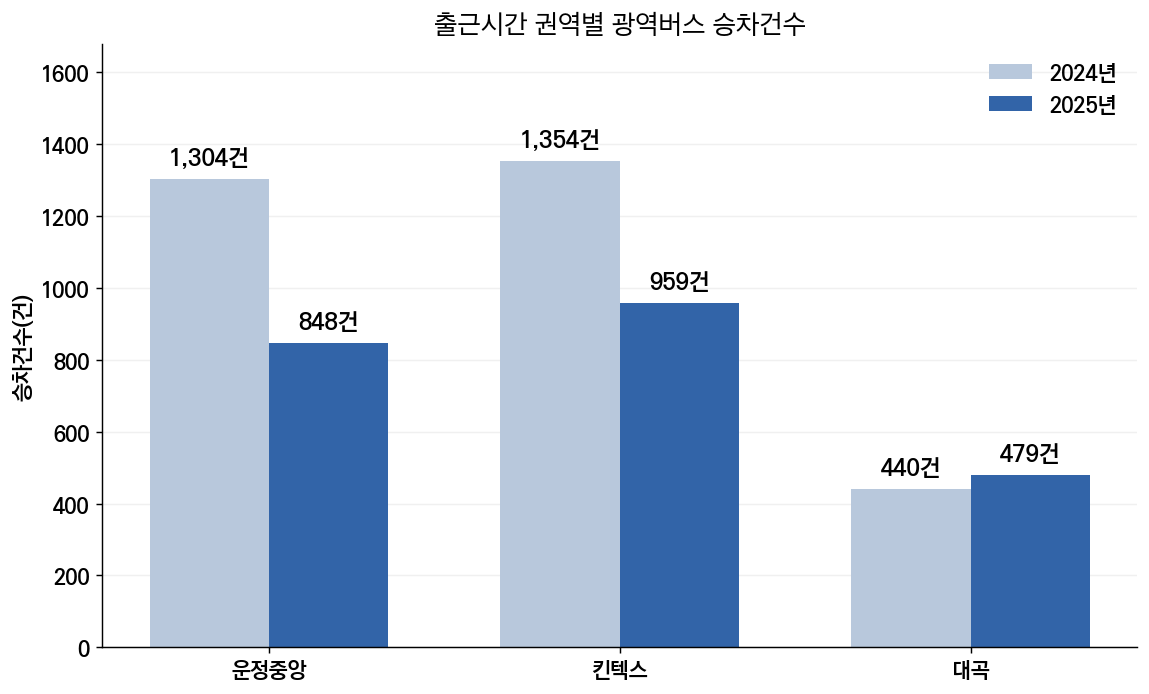

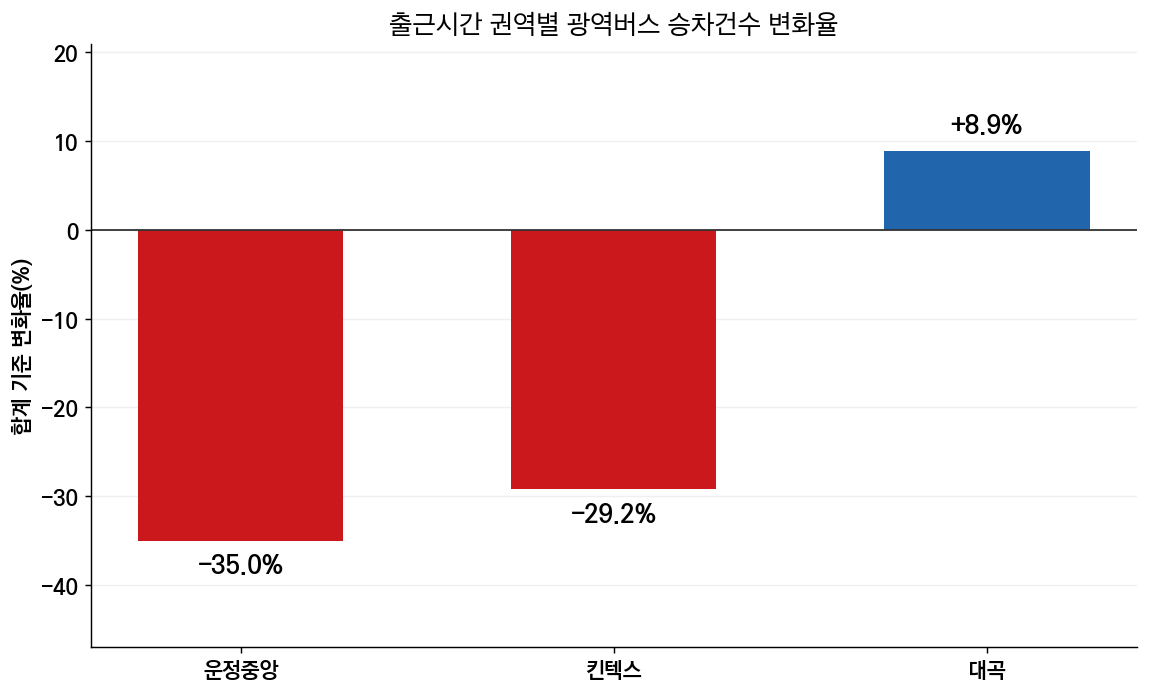

,종일 건수,출근시간 건수,그 외 시간 건수,출근시간 비율(%),그 외 시간 비율(%)
연도,,,,,
2024,7110.0,3098.0,4012.0,43.57,56.43
2025,5517.0,2286.0,3231.0,41.44,58.56


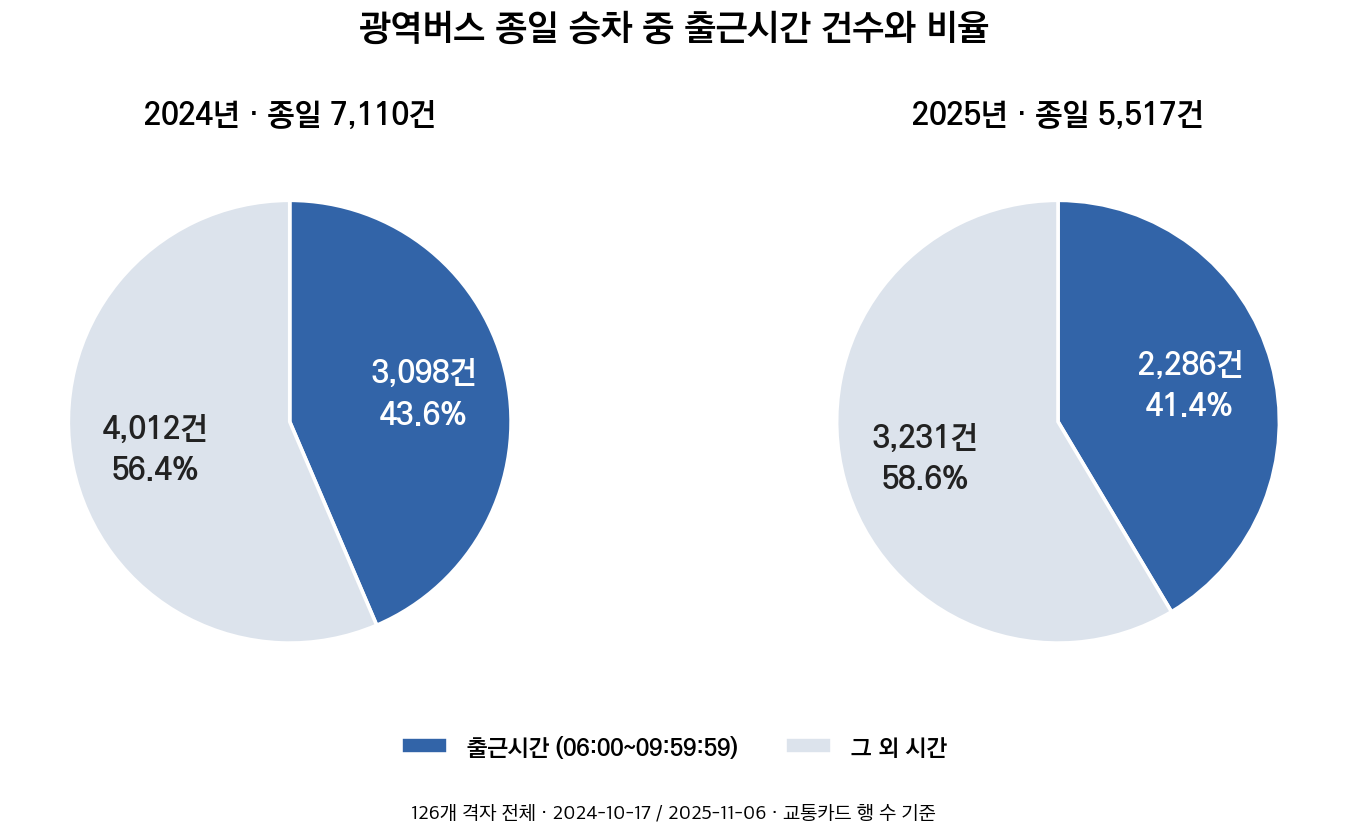

In [3]:
region_014=grid_014.groupby('nearest_station').agg(
    격자수=('출근_변화량','size'),개통전=('출근_2024','sum'),개통후=('출근_2025','sum'),
    변화량=('출근_변화량','sum'),개통전0건격자=('출근_2024',lambda x:int(x.eq(0).sum()))).reindex(ORDER_014)
region_014.loc['전체']=region_014.sum()
region_014['변화율(%)']=100*region_014['변화량']/region_014['개통전'].replace(0,np.nan)
display(region_014.round(2))
fig,ax=plt.subplots(figsize=(9,5.5));x=np.arange(3);w=.34
for off,col,label,color in [(-w/2,'개통전','2024년','#B8C8DC'),(w/2,'개통후','2025년','#3264A8')]:
    vals=region_014.loc[ORDER_014,col];bars=ax.bar(x+off,vals,w,label=label,color=color)
    ax.bar_label(bars,labels=[f'{int(v):,}건' for v in vals],padding=5,fontsize=13,fontweight='bold')
ax.set_xticks(x,ORDER_014);ax.set_ylim(0,region_014.loc[ORDER_014,['개통전','개통후']].max().max()*1.24)
ax.set_title('출근시간 권역별 광역버스 승차건수');ax.set_ylabel('승차건수(건)');ax.legend(frameon=False)
clean_axes_014(ax);fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,5.5));vals=region_014.loc[ORDER_014,'변화율(%)']
bars=ax.bar(ORDER_014,vals,color=[COLORS_014['감소'] if v<0 else COLORS_014['증가'] if v>0 else COLORS_014['유지'] for v in vals],width=.55)
ax.axhline(0,color='#333333',lw=1);ax.set_ylim(min(0,vals.min())-12,max(0,vals.max())+12)
for bar,value in zip(bars,vals):
    ax.annotate(f'{value:+.1f}%',(bar.get_x()+bar.get_width()/2,value),xytext=(0,-7 if value<0 else 7),
                textcoords='offset points',ha='center',va='top' if value<0 else 'bottom',fontsize=14,fontweight='bold')
ax.set_title('출근시간 권역별 광역버스 승차건수 변화율');ax.set_ylabel('합계 기준 변화율(%)')
clean_axes_014(ax);fig.tight_layout();plt.show()

# 추가 그림: 126개 전체 격자의 종일 승차 중 출근시간 승차 비율
# 비율의 분모는 각 연도의 종일 건수이며, 전체 감소량 중 출근 감소량의 비중과 다르다.
daypart_014=pd.DataFrame(index=pd.Index([2024,2025],name='연도'))
for year in [2024,2025]:
    daypart_014.loc[year,'종일 건수']=int(base_014[f'board_{year}'].sum())
    daypart_014.loc[year,'출근시간 건수']=int(grid_014[f'출근_{year}'].sum())
daypart_014['그 외 시간 건수']=daypart_014['종일 건수']-daypart_014['출근시간 건수']
assert daypart_014['그 외 시간 건수'].ge(0).all()
daypart_014['출근시간 비율(%)']=100*daypart_014['출근시간 건수']/daypart_014['종일 건수']
daypart_014['그 외 시간 비율(%)']=100-daypart_014['출근시간 비율(%)']
print('분모: 각 연도 126개 격자의 종일 승차건수 / 분자: 해당 연도 06:00~09:59:59 승차건수')
display(daypart_014.round(2))
fig,axes=plt.subplots(1,2,figsize=(12,6.5))
for ax,(year,row) in zip(axes,daypart_014.iterrows()):
    values=[row['출근시간 건수'],row['그 외 시간 건수']]
    wedges,texts,autotexts=ax.pie(
        values,colors=['#3264A8','#DCE3EC'],startangle=90,counterclock=False,
        autopct='%1.1f%%',pctdistance=.62,
        wedgeprops={'edgecolor':'white','linewidth':2},
        textprops={'fontsize':17,'fontweight':'bold'})
    for j,text in enumerate(autotexts):
        text.set_text(f'{int(values[j]):,}건\n{100*values[j]/sum(values):.1f}%')
        text.set_color('white' if j==0 else '#222222')
        text.set_linespacing(1.5)
        bold_label_014(text)
    ax.set_title(f'{year}년 · 종일 {int(row["종일 건수"]):,}건',fontsize=17,pad=12,fontweight='bold')
    bold_label_014(ax.title)
    ax.set_aspect('equal')
fig.suptitle('광역버스 종일 승차 중 출근시간 건수와 비율',fontsize=20,fontweight='bold',y=.98)
bold_label_014(fig._suptitle)
legend=fig.legend(wedges,['출근시간 (06:00~09:59:59)','그 외 시간'],
                 frameon=False,loc='lower center',bbox_to_anchor=(.5,.07),ncol=2,fontsize=13)
for text in legend.get_texts():bold_label_014(text)
fig.tight_layout(rect=[0,.14,1,.92])
fig.text(.5,.025,'126개 격자 전체 · 2024-10-17 / 2025-11-06 · 교통카드 행 수 기준',ha='center',fontsize=11)
plt.show()


## 3. 격자별 기초통계와 변화율 분포

출근 2024년·2025년 건수와 변화량은 **126개**, 변화율은 **2024년 출근 승차가 1건 이상인 격자**에 대해 제시한다. 변화율 미정의는 0%나 누락된 분석대상으로 취급하지 않고 별도 표에 표시한다. 분포 그림에는 유한한 변화율을 모두 넣으며 극단값을 절단하지 않는다.

변화량에 따른 감소·유지·증가 격자 수
개통 전 0건: 변화율 산출 불가 13 개 (변화량·합계에는 포함)


,출근_2024,출근_2025,출근_변화량,출근_변화율(%)
유효 격자 수,126.00,126.00,126.00,113.00
평균,24.59,18.14,-6.44,-15.16
표준편차,41.55,30.64,16.19,54.50
최소,0.00,0.00,-92.00,-100.00
1사분위,3.00,2.00,-7.75,-50.00
중앙값,10.50,9.00,-1.50,-25.58
3사분위,26.00,16.75,1.00,11.76
최대,264.00,172.00,38.00,200.00


변화 구분,감소,유지,증가
nearest_station,,,
운정중앙,38,10,15
킨텍스,20,1,5
대곡,15,5,17
전체,73,16,37


,셀 ID,nearest_station,출근_2024,출근_2025,출근_변화량,출근_변화율(%)
0,1962,대곡,0,1,1,NaN
1,7368,대곡,0,2,2,NaN
2,8805,대곡,0,1,1,NaN
3,9285,대곡,0,0,0,NaN
4,14004,대곡,0,2,2,NaN
5,76,운정중앙,0,2,2,NaN
6,2295,운정중앙,0,0,0,NaN
7,4714,운정중앙,0,2,2,NaN
8,4768,운정중앙,0,1,1,NaN
9,7262,운정중앙,0,0,0,NaN


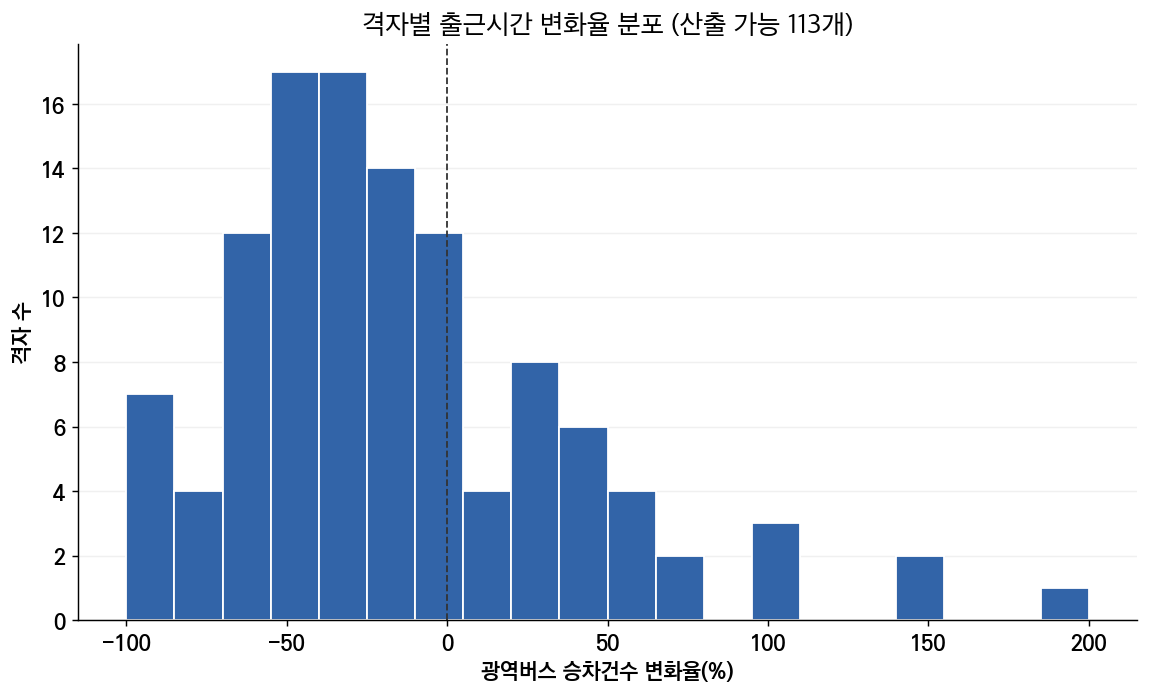

In [4]:
stat_columns_014=['출근_2024','출근_2025','출근_변화량','출근_변화율(%)']
display(grid_014[stat_columns_014].describe(percentiles=[.25,.5,.75]).rename(index={
    'count':'유효 격자 수','mean':'평균','std':'표준편차','min':'최소','25%':'1사분위','50%':'중앙값','75%':'3사분위','max':'최대'}).round(2))
direction_014=pd.crosstab(grid_014['nearest_station'],grid_014['변화 구분']).reindex(index=ORDER_014,columns=['감소','유지','증가'],fill_value=0)
direction_014.loc['전체']=direction_014.sum()
print('변화량에 따른 감소·유지·증가 격자 수');display(direction_014)
zero_014=grid_014.loc[grid_014['출근_2024'].eq(0)].reset_index()
print('개통 전 0건: 변화율 산출 불가',len(zero_014),'개 (변화량·합계에는 포함)')
display(zero_014[['셀 ID','nearest_station','출근_2024','출근_2025','출근_변화량','출근_변화율(%)']])
fig,ax=plt.subplots(figsize=(9,5.5));rates=grid_014['출근_변화율(%)'].dropna()
ax.hist(rates,bins=20,color='#3264A8',edgecolor='white')
ax.axvline(0,color='#333333',ls='--',lw=1)
ax.set_title(f'격자별 출근시간 변화율 분포 (산출 가능 {len(rates)}개)')
ax.set_xlabel('광역버스 승차건수 변화율(%)');ax.set_ylabel('격자 수')
clean_axes_014(ax);fig.tight_layout();plt.show()

## 4. 소규모 기초건수와 극단적인 변화율

2024년 건수가 작으면 몇 건의 변화만으로도 큰 변화율이 나타날 수 있다. **어떤 격자도 분석에서 임의 제외하지 않는다.** 아래 ‘20건 미만’ 표시는 해석용 표시이며 표본 선택이나 유의성 기준이 아니다. 실제 전후 건수와 절대 변화량을 함께 확인한다.

절대 변화율 상위 15개 격자: 순위 선정은 표시용, 분석 제외 기준 아님


,셀 ID,nearest_station,출근_2024,출근_2025,출근_변화량,출근_변화율(%),소규모 기초건수 주의
0,6952,운정중앙,1,3,2,200.0,2024년 20건 미만
1,5964,운정중앙,2,5,3,150.0,2024년 20건 미만
2,13631,운정중앙,4,10,6,150.0,2024년 20건 미만
3,1235,대곡,1,0,-1,-100.0,2024년 20건 미만
4,6398,대곡,3,6,3,100.0,2024년 20건 미만
5,10471,대곡,1,0,-1,-100.0,2024년 20건 미만
6,11191,대곡,1,0,-1,-100.0,2024년 20건 미만
7,12985,대곡,2,4,2,100.0,2024년 20건 미만
8,3056,운정중앙,3,0,-3,-100.0,2024년 20건 미만
9,8689,운정중앙,1,2,1,100.0,2024년 20건 미만


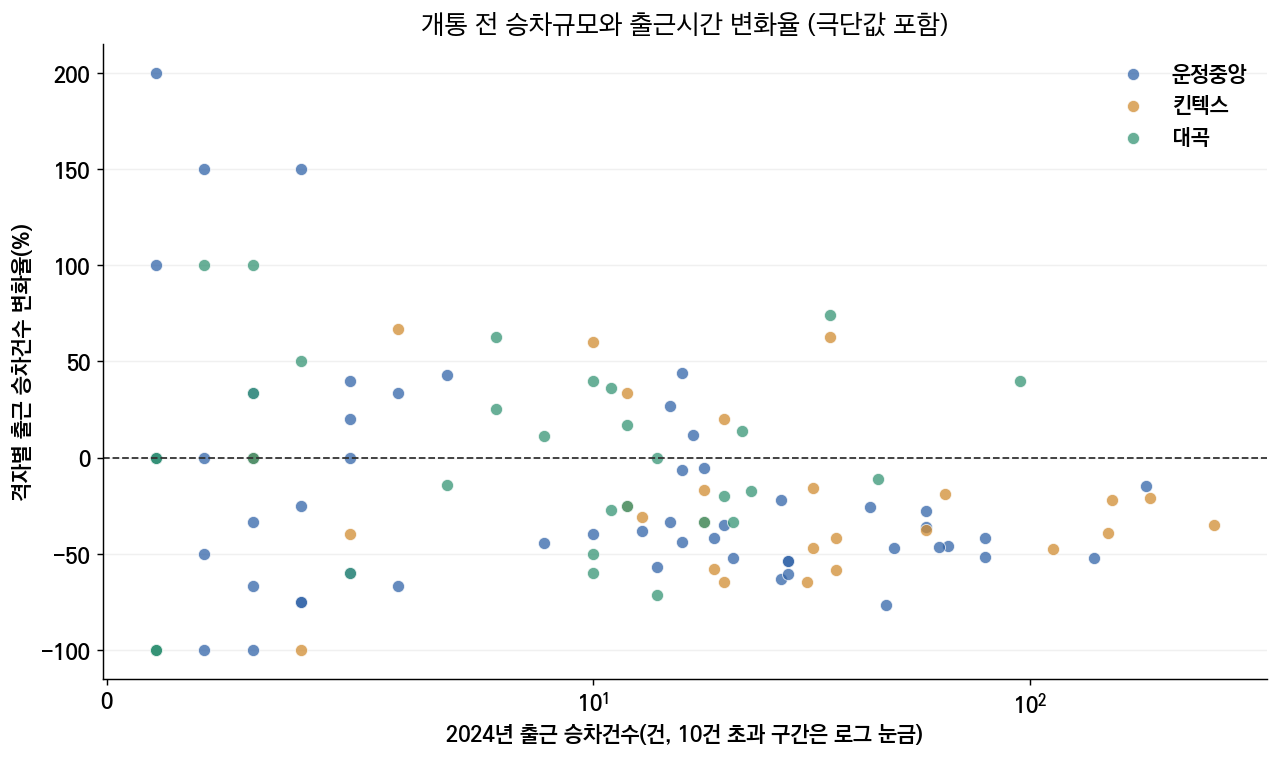

In [5]:
grid_014['소규모 기초건수 주의']=np.select([grid_014['출근_2024'].eq(0),grid_014['출근_2024'].lt(20)],
    ['2024년 0건: 변화율 미정의','2024년 20건 미만'],default='')
extreme_014=grid_014.loc[grid_014['출근_변화율(%)'].notna()].copy()
extreme_014=extreme_014.loc[extreme_014['출근_변화율(%)'].abs().sort_values(ascending=False,kind='stable').index]
print('절대 변화율 상위 15개 격자: 순위 선정은 표시용, 분석 제외 기준 아님')
display(extreme_014.reset_index()[['셀 ID','nearest_station','출근_2024','출근_2025','출근_변화량',
                                 '출근_변화율(%)','소규모 기초건수 주의']].head(15).round(2))
fig,ax=plt.subplots(figsize=(10,6))
for st in ORDER_014:
    part=grid_014.loc[grid_014['nearest_station'].eq(st)&grid_014['출근_변화율(%)'].notna()]
    ax.scatter(part['출근_2024'],part['출근_변화율(%)'],label=st,color=REGION_COLORS_014[st],
               alpha=.75,s=45,edgecolor='white',linewidth=.5)
ax.set_xscale('symlog',linthresh=10)
ax.axhline(0,color='#333333',ls='--',lw=1);ax.legend(frameon=False)
ax.set_xlabel('2024년 출근 승차건수(건, 10건 초과 구간은 로그 눈금)')
ax.set_ylabel('격자별 출근 승차건수 변화율(%)')
ax.set_title('개통 전 승차규모와 출근시간 변화율 (극단값 포함)')
clean_axes_014(ax);fig.tight_layout();plt.show()

## 5. 노선별 출근시간 승차건수 변화율

- 126개 격자에 **종일 승차 기록이 있는 전체 후보 노선**을 기준으로 출근시간 실적을 연결한다. 출근 두 날짜 모두 0건인 노선도 표에 남긴다.
- 노선별 **2024년·2025년 출근 건수, 변화량, 변화율, 종일 변화율**을 함께 표시한다.
- 2024년 출근 0건이면 변화율은 산출하지 않는다. 2025년만 기록이 있다고 실제 신설 노선으로 단정하지 않는다.
- 그래프에서 **감소는 빨강, 증가는 파랑, 유지는 회색**이다. 미정의 변화율은 ‘산출 불가’로 표시한다.

In [6]:
route_all_counts_014={year:all_selected_014[year].groupby('노선번호').size() for year in [2024,2025]}
route_morning_counts_014={year:morning_selected_014[year].groupby('노선번호').size() for year in [2024,2025]}
all_route_names_014=sorted(set(route_all_counts_014[2024].index)|set(route_all_counts_014[2025].index))
route_014=pd.DataFrame(index=pd.Index(all_route_names_014,name='노선번호'))
for year in [2024,2025]:
    route_014[f'{year}년 출근건수']=route_morning_counts_014[year].reindex(route_014.index,fill_value=0).astype(int)
    route_014[f'{year}년 종일건수']=route_all_counts_014[year].reindex(route_014.index,fill_value=0).astype(int)
    assert route_014[f'{year}년 출근건수'].sum()==grid_014[f'출근_{year}'].sum()
    assert route_014[f'{year}년 종일건수'].sum()==base_014[f'board_{year}'].sum()
route_014['출근 변화량(건)']=route_014['2025년 출근건수']-route_014['2024년 출근건수']
route_014['출근 변화율(%)']=100*route_014['출근 변화량(건)']/route_014['2024년 출근건수'].replace(0,np.nan)
route_014['종일 변화율(%)']=100*(route_014['2025년 종일건수']-route_014['2024년 종일건수'])/route_014['2024년 종일건수'].replace(0,np.nan)
route_014['해석 주의']=np.select([
    route_014['2024년 출근건수'].eq(0)&route_014['2025년 출근건수'].eq(0),
    route_014['2024년 출근건수'].eq(0),route_014['2024년 출근건수'].lt(20)],
    ['양일 출근 0건: 변화율 미정의','2024년 출근 0건: 변화율 미정의','2024년 출근 20건 미만'],default='')
route_014=route_014.sort_values('출근 변화율(%)',kind='stable',na_position='last')
print(f'전체 후보 {len(route_014)}개 노선 · 출근 변화율 산출 가능 {route_014["출근 변화율(%)"].notna().sum()}개')
print('노선별 합계 = 격자별 합계 일치 확인 · 노선 전체 구간 실적 아님')
display(route_014[['2024년 출근건수','2025년 출근건수','출근 변화량(건)','출근 변화율(%)',
                  '2024년 종일건수','2025년 종일건수','종일 변화율(%)','해석 주의']].round(2))
route_direction_014=np.select([route_014['출근 변화량(건)'].lt(0),route_014['출근 변화량(건)'].gt(0)],['감소','증가'],default='유지')
print('출근 변화량 기준 노선 수 (양일 0건은 유지에 포함):')
display(pd.Series(route_direction_014).value_counts().reindex(['감소','유지','증가'],fill_value=0).rename('노선 수').to_frame())

전체 후보 24개 노선 · 출근 변화율 산출 가능 24개
노선별 합계 = 격자별 합계 일치 확인 · 노선 전체 구간 실적 아님
출근 변화량 기준 노선 수 (양일 0건은 유지에 포함):


,2024년 출근건수,2025년 출근건수,출근 변화량(건),출근 변화율(%),2024년 종일건수,2025년 종일건수,종일 변화율(%),해석 주의
노선번호,,,,,,,,
3400,229,94,-135,-58.95,361,173,-52.08,
M7154,90,38,-52,-57.78,154,75,-51.30,
9030-1,11,6,-5,-45.45,15,9,-40.00,2024년 출근 20건 미만
7101,141,80,-61,-43.26,217,137,-36.87,
G7625,128,73,-55,-42.97,246,156,-36.59,
9700,19,11,-8,-42.11,34,24,-29.41,2024년 출근 20건 미만
2200,158,95,-63,-39.87,437,365,-16.48,
1500,186,116,-70,-37.63,466,304,-34.76,
1200,366,251,-115,-31.42,727,516,-29.02,


,노선 수
감소,18
유지,1
증가,5


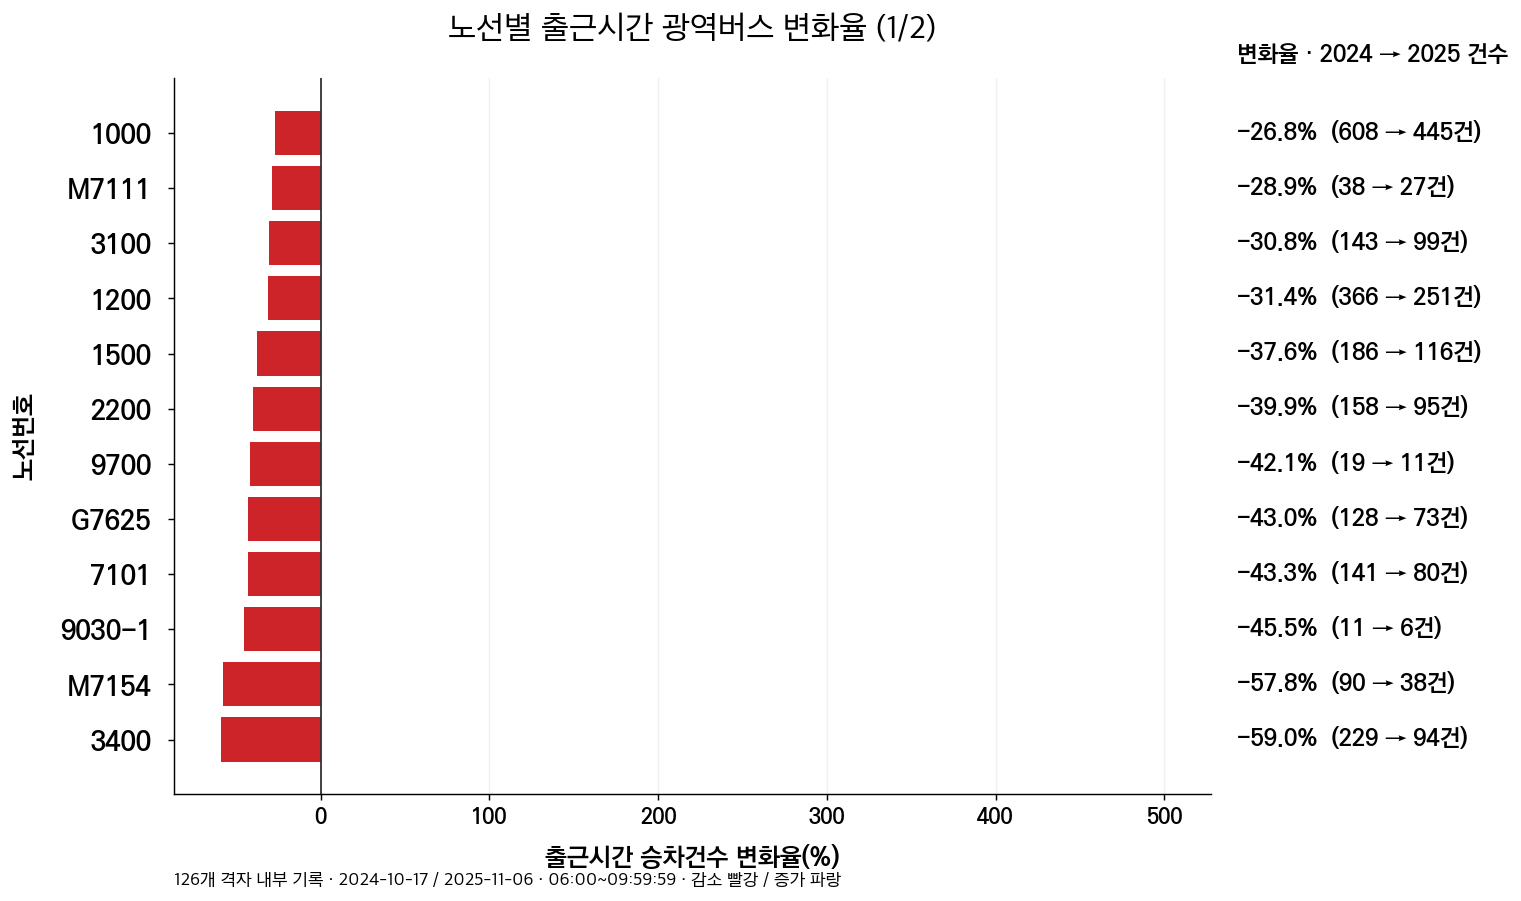

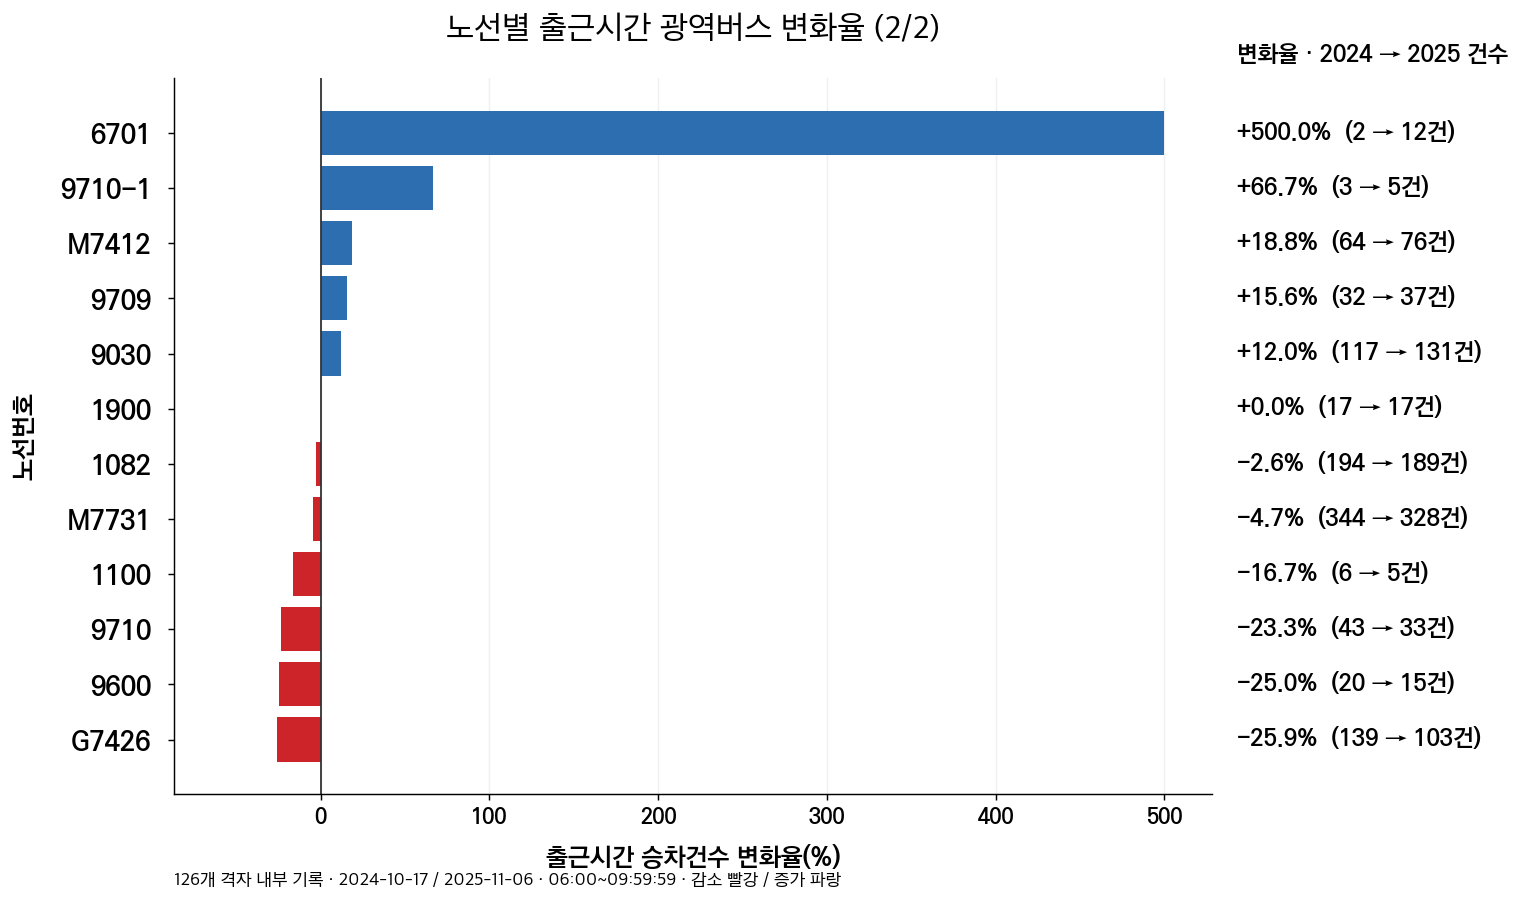

In [7]:
finite_014=route_014['출근 변화율(%)'].dropna()
low_014=min(0,float(finite_014.min())) if len(finite_014) else 0
high_014=max(0,float(finite_014.max())) if len(finite_014) else 0
padding_014=max(5,(high_014-low_014)*.05)
mid_014=int(np.ceil(len(route_014)/2))
for number,part in enumerate([route_014.iloc[:mid_014],route_014.iloc[mid_014:]],1):
    if part.empty:continue
    fig,ax=plt.subplots(figsize=(14,max(6.3,len(part)*.62)))
    vals=part['출근 변화율(%)']
    colors=[COLORS_014['유지'] if pd.isna(v) or v==0 else COLORS_014['감소'] if v<0 else COLORS_014['증가'] for v in vals]
    # 미정의는 막대를 그리지 않는다. 실제 0%와 구분하여 오른쪽에 '산출 불가'를 표시.
    y=np.arange(len(part));ok=vals.notna().to_numpy()
    ax.barh(y[ok],vals.to_numpy()[ok],color=np.array(colors)[ok],alpha=.95)
    ax.set_yticks(y,part.index);ax.axvline(0,color='#333333',lw=1)
    ax.set_xlim(low_014-padding_014,high_014+padding_014)
    ax.set_xlabel('출근시간 승차건수 변화율(%)',fontsize=14,labelpad=10)
    ax.set_ylabel('노선번호',fontsize=14,labelpad=12)
    ax.set_title(f'노선별 출근시간 광역버스 변화율 ({number}/2)',fontsize=18,fontweight='bold',pad=22)
    ax.tick_params(axis='y',labelsize=15,pad=9);ax.tick_params(axis='x',labelsize=12)
    for label in ax.get_yticklabels():label.set_fontweight('bold')
    ax.text(1.025,1.025,'변화율 · 2024 → 2025 건수',transform=ax.transAxes,fontsize=13,fontweight='bold')
    for j,(_,row) in enumerate(part.iterrows()):
        rate=row['출근 변화율(%)']
        label=f'{rate:+.1f}%' if pd.notna(rate) else '산출 불가'
        label+=f'  ({int(row["2024년 출근건수"]):,} → {int(row["2025년 출근건수"]):,}건)'
        ax.text(1.025,j,label,transform=ax.get_yaxis_transform(),ha='left',va='center',
                fontsize=13,fontweight='bold',clip_on=False)
    clean_axes_014(ax)
    ax.grid(axis='y',visible=False);ax.grid(axis='x',alpha=.18)
    fig.subplots_adjust(left=.13,right=.70,top=.87,bottom=.13)
    fig.text(.13,.035,'126개 격자 내부 기록 · 2024-10-17 / 2025-11-06 · '+TIME_014+' · 감소 빨강 / 증가 파랑',fontsize=10)
    plt.show()

## 6. 미팅에서 설명할 순서와 해석 범위

1. 전체·권역별 전후 승차건수와 **합계 변화율**을 먼저 설명한다.
2. 격자별 기초통계와 감소·유지·증가 수를 보여주고, **2024년 0건 격자의 변화율은 미정의**임을 설명한다.
3. **노선별 변화율과 실제 전후 건수**를 같이 보여준다. 작은 분모 때문에 큰 변화율이 나타난 노선은 노선번호와 실제 건수로 설명한다.
4. 노선별 값은 분석격자 내부 승차 기록의 변화다. 노선의 전체 수요 변화나 실제 신설·폐선 여부로 확대 해석하지 않는다.
5. 이후 013의 종일·출근시간 회귀로 넘어간다. 기초통계는 **변화율도 제시**하지만 광역버스 회귀의 종속변수는 **변화량(건)**이다.

126개 전체의 출근 승차건수는 **3,098 → 2,286건**, 변화량은 **−812건**, 합계 변화율은 **−26.2%**다. 2024년 출근 0건 13개는 모든 건수 집계에 포함되고, 격자별 변화율만 산출하지 않는다. 기존 노트북과 원자료는 변경하지 않는다.

## 7. 시간대별 광역버스 승차건수 변화율 (5~23시)

126개 전체 격자에서 승차시각별로 집계한 **5시대~23시대 막대그래프**다. 예를 들어 7시는 07:00:00~07:59:59다. 출근시간에 해당하는 6·7·8·9시대는 음영으로 표시한다.

- 각 시간대 **2024년 건수 대비 2025년 변화율(%)**을 막대로 표시하고, 퍼센트 아래에 **변화량(±몇 건)**을 함께 적는다.
- 감소는 빨강·증가는 파랑이며 축 눈금과 수치 레이블은 굵게 표시한다.
- 2024년 0건이면 변화율은 미산출로 표시한다. 격자별 변화율을 평균한 값이 아니라 시간대별 합계의 변화율이다.
- 종일 합계 검증은 0~23시 전체로 유지하며, 표시 범위만 5~23시로 제한한다. 권역별 선그래프는 표시하지 않는다.
- 원자료 영업일 기준을 유지하므로 다음 날 자정 이후 기록은 같은 승차 시각 구간에 합산한다.


24시간 합계 = 종일 합계 / 6~9시대 합계 = 기존 출근시간 합계 일치 확인


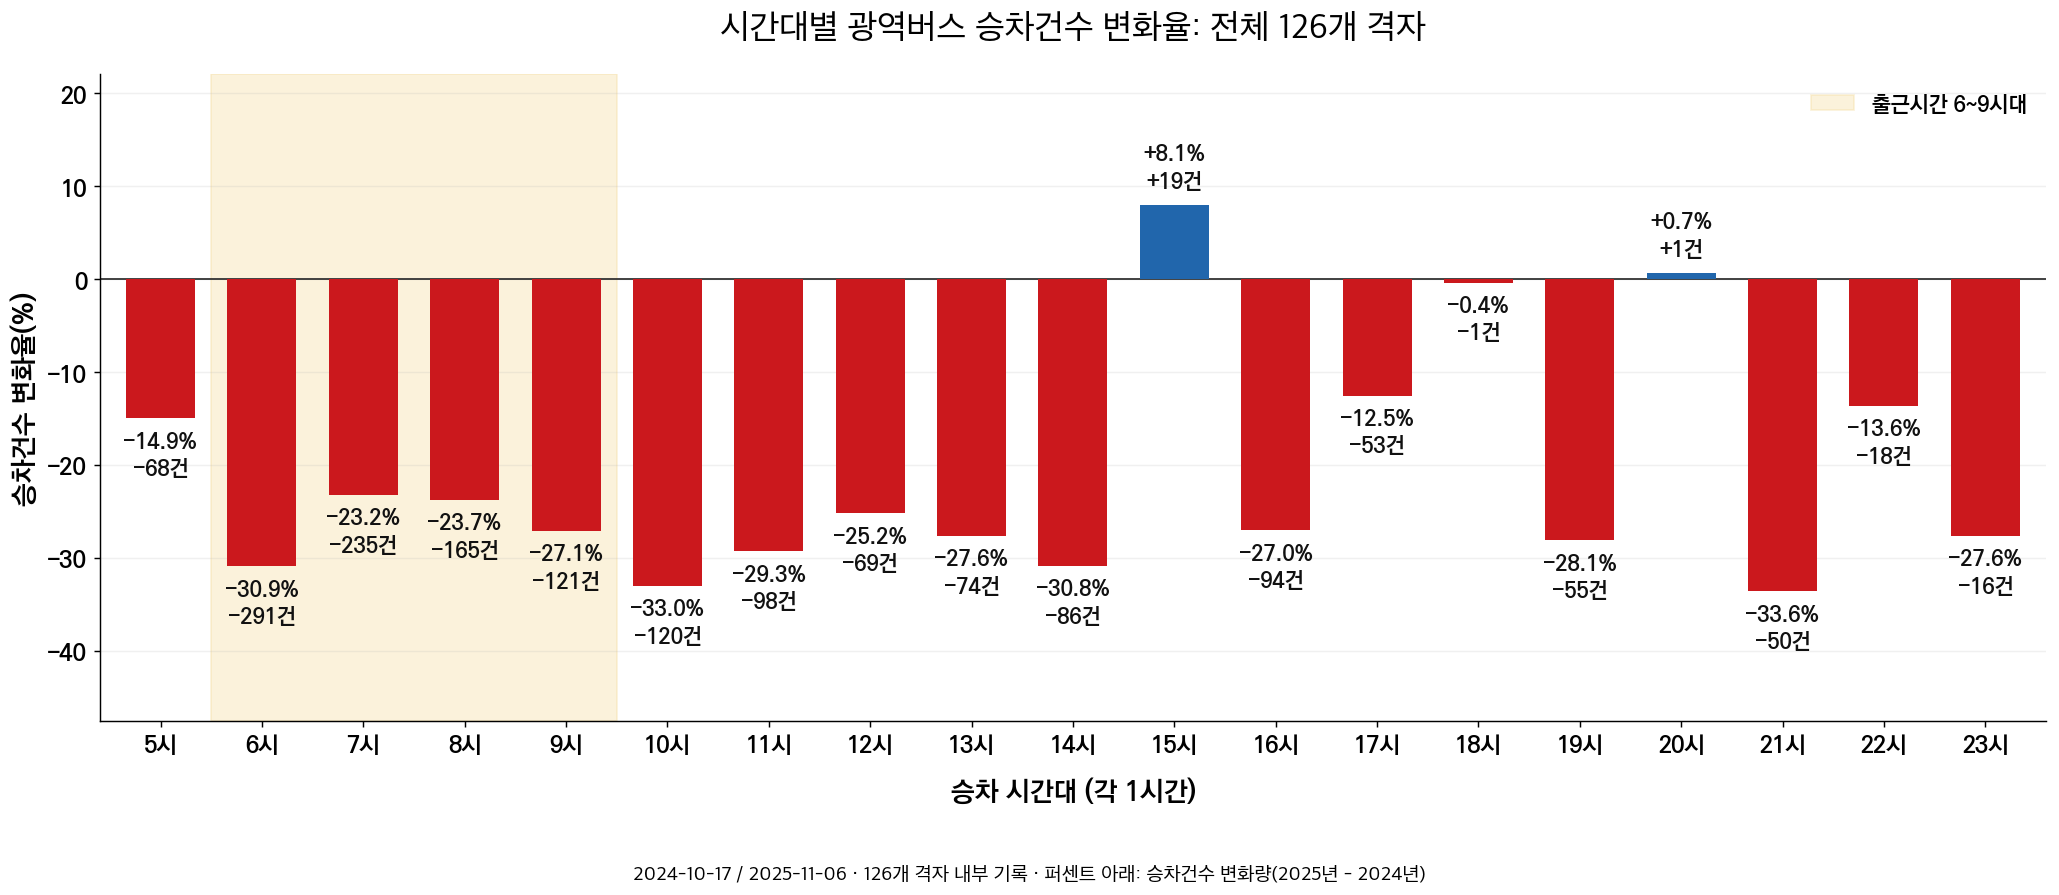

In [8]:
hour_index_014=pd.MultiIndex.from_product([['전체',*ORDER_014],range(24)],names=['권역','시간'])
hourly_014=pd.DataFrame(index=hour_index_014)
for year in [2024,2025]:
    part=all_selected_014[year].copy()
    part['권역']=part['셀 ID'].map(base_014['nearest_station'])
    assert part['권역'].notna().all()
    rows=[]
    for station in ['전체',*ORDER_014]:
        sub=part if station=='전체' else part.loc[part['권역'].eq(station)]
        counts=sub.groupby('승차시간').size().reindex(range(24),fill_value=0)
        rows.extend([(station,h,int(value)) for h,value in counts.items()])
    counts=pd.DataFrame(rows,columns=['권역','시간',f'{year}년 건수']).set_index(['권역','시간'])
    hourly_014[f'{year}년 건수']=counts[f'{year}년 건수'].reindex(hour_index_014).astype(int)
    assert hourly_014.loc['전체',f'{year}년 건수'].sum()==base_014[f'board_{year}'].sum()

hourly_014=hourly_014.sort_index()
hourly_014['변화량(건)']=hourly_014['2025년 건수']-hourly_014['2024년 건수']
hourly_014['변화율(%)']=100*hourly_014['변화량(건)']/hourly_014['2024년 건수'].replace(0,np.nan)
hourly_014['해석 주의']=np.select([hourly_014['2024년 건수'].eq(0),hourly_014['2024년 건수'].lt(20)],
    ['2024년 0건: 변화율 미정의','2024년 20건 미만'],default='')
for station in ['전체',*ORDER_014]:
    summed=hourly_014.loc[station].loc[6:9,['2024년 건수','2025년 건수','변화량(건)']].sum()
    np.testing.assert_array_equal(summed.to_numpy(),region_014.loc[station,['개통전','개통후','변화량']].to_numpy())
print('24시간 합계 = 종일 합계 / 6~9시대 합계 = 기존 출근시간 합계 일치 확인')
# 그래프는 5시대부터 23시대까지만 표시한다. 전체 집계·검증은 24시간을 유지한다.
whole=hourly_014.loc['전체'].loc[5:23]
hours=whole.index.to_numpy();values=whole['변화율(%)']
finite=values.notna().to_numpy()
fig,ax=plt.subplots(figsize=(16,7))
colors=[COLORS_014['감소'] if v<0 else COLORS_014['증가'] if v>0 else COLORS_014['유지'] for v in values[finite]]
ax.axvspan(5.5,9.5,color='#F4DA9A',alpha=.35,zorder=0,label='출근시간 6~9시대')
ax.bar(hours[finite],values.to_numpy()[finite],color=colors,width=.68,zorder=3)
ax.axhline(0,color='#333333',lw=1)
valid=values.dropna()
lo=min(0,float(valid.min())) if len(valid) else 0
hi=max(0,float(valid.max())) if len(valid) else 0
pad=max(14,(hi-lo)*.3)
ax.set_ylim(lo-pad,hi+pad)
for h,row in whole.iterrows():
    v=row['변화율(%)'];change=int(row['변화량(건)'])
    label=(f'{v:+.1f}%' if pd.notna(v) else '미산출')+f'\n{change:+,}건'
    if pd.notna(v):
        ax.annotate(label,(h,v),xytext=(0,-7 if v<0 else 7),textcoords='offset points',
                    ha='center',va='top' if v<0 else 'bottom',fontsize=12,fontweight='bold',
                    color='#111111',linespacing=1.4)
    else:
        ax.annotate(label,(h,0),xytext=(0,7),textcoords='offset points',ha='center',va='bottom',
                    fontsize=12,fontweight='bold',color='#666666',linespacing=1.4)
ax.set_xticks(hours,[f'{h}시' for h in hours]);ax.set_xlim(4.4,23.6)
ax.tick_params(axis='both',labelsize=13)
ax.set_ylabel('승차건수 변화율(%)',fontsize=15)
ax.set_xlabel('승차 시간대 (각 1시간)',fontsize=15,labelpad=12)
ax.set_title('시간대별 광역버스 승차건수 변화율: 전체 126개 격자',fontsize=19,pad=20)
ax.legend(frameon=False,loc='upper right',fontsize=12)
clean_axes_014(ax)
fig.tight_layout(rect=[0,.075,1,1])
fig.text(.5,.02,'2024-10-17 / 2025-11-06 · 126개 격자 내부 기록 · 퍼센트 아래: 승차건수 변화량(2025년 - 2024년)',
         ha='center',fontsize=11)
plt.show()
